# КТ 3 — векторная база, эмбеддинги и sparse/dense/hybrid поиск

Решения и выводы — в `reports/kt3.md`, здесь — эксперименты и цифры.

**Baseline из КТ 2 (не пересматривается):** предобработка — все шаги, кроме удаления подписей Telegram
(без него validation был лучше по всем метрикам обоих поисковиков); чанкер — RecursiveChunker(512)
по токенам BGE-M3 (не хуже остальных и не рвёт абзацы). Для плотного поиска к чанку приписывается строка
метаданных «заголовок | тип | патч | дата» (в КТ 2 она подняла dense R@5 с 48,8 до 53,3), BM25 индексирует
чистый текст (префикс ему вредил).

**Метрики** — как в КТ 2 (`gigarag.metrics`), плюс NDCG@k с оценками 2/1 и MAP (AP@10). Все решения —
по validation (29 вопросов с доказательствами); test — только в итоговой таблице. Негативные вопросы
доказательств не имеют: для них считается `near@5` — доля чанков «по теме, но без ответа» в топ-5.

In [1]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.stats import spearmanr

import gigarag.chunking
import gigarag.cleaning
import gigarag.metadata
import gigarag.noise
import gigarag.patterns
import gigarag.retrieval
from gigarag import cleaning, fusion, metadata, metrics, tokens, vectordb
from gigarag.cache import (
    CacheStore,
    array_fingerprint,
    code_fingerprint,
    load_or_compute,
    load_or_compute_timed,
    read_json,
    read_npy,
    read_parquet,
    timed,
    write_json,
    write_npy,
    write_parquet,
)
from gigarag.chunking import ChunkerResources, ChunkerSpec, build_chunker, chunk_documents, chunks_frame, frame_chunks
from gigarag.corpus import Document, read_jsonl
from gigarag.embeddings import EmbedderSpec, encode, load_sentence_model, model_size_mb, query_latencies
from gigarag.experiment import docs_fingerprint, texts_fingerprint
from gigarag.gold import load_gold
from gigarag.profiling import traced_peak_mb
from gigarag.relevance import build_qrels
from gigarag.retrieval import Bm25Index, bm25_tokens, top_k
from gigarag.search import masked_top_k, ranked_ids
from gigarag.vectordb import IndexConfig, QdrantContainer, build_collection

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 220)
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd().parent  # ноутбук исполняется из notebooks/
DATA = ROOT / "data"
rows, CORPUS_SHA = read_jsonl(DATA / "corpus.jsonl")
raw_docs = tuple(Document(**r) for r in rows)
items = load_gold(ROOT / "gold" / "gold.jsonl")
cache = CacheStore(DATA / "cache" / "kt3", CORPUS_SHA)

BGE_M3, BGE_M3_REV = "BAAI/bge-m3", "5617a9f61b028005a4858fdac845db406aefb181"
DEPTH = 10      # выдача для метрик
POOL = 100      # кандидаты каждого поисковика для слияния
SEED = 42
tokenizer = tokens.load_tokenizer(BGE_M3, BGE_M3_REV)

## 1. Корпус и чанки — baseline КТ 2

In [2]:
CHUNKER = ChunkerSpec("recursive", chunk_size=512)
clean = cleaning.run_stages(cleaning.CleanCorpus(raw_docs),
                            [s for s in cleaning.PIPELINE if s.name != "signatures"])[-1][1]
CHUNK_CODE = code_fingerprint(gigarag.patterns, gigarag.cleaning, gigarag.chunking)


def make_chunks() -> pd.DataFrame:
    chunks = chunk_documents(clean.docs, build_chunker(CHUNKER, ChunkerResources(tokenizer)))
    return chunks_frame(chunks, tokens.token_counts(tokenizer, [c.text for c in chunks]))


chunk_frame = load_or_compute(cache.path("chunks", "parquet", docs=docs_fingerprint(clean.docs), code=CHUNK_CODE,
                                         **CHUNKER.params()), make_chunks, load=read_parquet, save=write_parquet)
chunks = frame_chunks(chunk_frame)
texts = [c.text for c in chunks]
qrels = build_qrels(items, chunks, clean.aliases)
meta = load_or_compute(
    cache.path("chunk_meta", "parquet", chunks=texts_fingerprint(texts),
               code=code_fingerprint(gigarag.metadata, gigarag.noise, gigarag.patterns), tokenizer=BGE_M3_REV),
    lambda: metadata.chunk_metadata(chunks, clean.docs, dict(zip(
        [d.doc_id for d in clean.docs], tokens.token_counts(tokenizer, [d.text for d in clean.docs]), strict=True)),
        tokens.offsets_fn(tokenizer)),
    load=read_parquet, save=write_parquet,
)
dense_texts = [metadata.with_metadata_prefix(t, row) for t, row in zip(texts, meta.to_dict("records"), strict=True)]
queries = {i.qid: i.question for i in items}
# 100 запросов для замера скорости: 50 вопросов gold в двух формулировках — после и до стилизации КТ 1.
latency_queries = [i.question for i in items] + [i.original_question or i.question for i in items]
print(f"{len(clean.docs)} документов → {len(chunks)} чанков; вопросов {len(items)}, запросов для замера "
      f"скорости {len(latency_queries)}")


def evaluate(config: str, retriever: str, rankings: dict) -> pd.DataFrame:
    """Метрики вопросов с доказательствами (qid → выдача) для одной конфигурации."""
    ids = {qid: ranked_ids(r) for qid, r in rankings.items()}
    return metrics.per_question(ids, qrels, items).assign(config=config, retriever=retriever)


def near_negatives(config: str, rankings: dict) -> pd.DataFrame:
    ids = {qid: ranked_ids(r) for qid, r in rankings.items()}
    return metrics.negative_per_question(ids, qrels, items).assign(config=config)


FINAL_COLUMNS = ["P@5", "R@5", "NDCG@5", "MAP", "MRR"]


def summary(per_q: pd.DataFrame, split: str = "validation", columns=FINAL_COLUMNS) -> pd.DataFrame:
    return (per_q[per_q["split"] == split].groupby("config", sort=False)[columns].mean() * 100).round(1)

19078 документов → 19773 чанков; вопросов 50, запросов для замера скорости 100


## 2. Эмбеддинг-модели

Три размера из MTEB RU плюс BGE-M3 из КТ 2 — четыре точки для проверки, коррелирует ли лидерборд
с нашим корпусом. Баллы ruMTEB — из Table 5 статьи про ruMTEB (Snegirev et al., 2024,
[arXiv 2408.12503](https://arxiv.org/abs/2408.12503)): все модели оценены авторами бенчмарка
в одном окружении, а не собраны из разных карточек.

| Роль | Модель | Почему она |
|---|---|---|
| лёгкая (< 100M) | `cointegrated/rubert-tiny2`, 29M | единственная модель < 100M в таблице ruMTEB; нижняя граница |
| средняя | `intfloat/multilingual-e5-base`, 278M | вдвое меньше тяжёлых, ruMTEB Avg 58,3 — баланс |
| baseline КТ 2 | `BAAI/bge-m3`, 567M | лучшая по Retrieval в ruMTEB (74,8), dense-поиск КТ 2 |
| тяжёлая | `intfloat/multilingual-e5-large-instruct`, 560M | лучшая по среднему ruMTEB (66,0) среди моделей до 1B |

`e5-mistral-7b-instruct` (ruMTEB 67,2) — единственная выше, но 7B в fp16 (14 ГБ) не помещается рядом
с другими процессами на RTX 5080 16 ГБ. Поиск во всех моделях — точный перебор (numpy): здесь сравниваются
модели, а не индексы.

In [3]:
E5_INSTRUCT = "Instruct: Given a web search query, retrieve relevant passages that answer the query\nQuery: "
EMBEDDERS = [
    EmbedderSpec("cointegrated/rubert-tiny2", "e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae", 29.4),
    EmbedderSpec("intfloat/multilingual-e5-base", "d128750597153bb5987e10b1c3493a34e5a4502a", 278,
                 query_prefix="query: ", passage_prefix="passage: "),
    EmbedderSpec(BGE_M3, BGE_M3_REV, 567),
    EmbedderSpec("intfloat/multilingual-e5-large-instruct", "274baa43b0e13e37fafa6428dbc7938e62e5c439", 560,
                 query_prefix=E5_INSTRUCT),
]
RUMTEB = {  # Table 5, arXiv 2408.12503: среднее по задачам и среднее по Retrieval
    "rubert-tiny2": (42.22, 8.89), "multilingual-e5-base": (58.34, 67.14),
    "bge-m3": (61.58, 74.79), "multilingual-e5-large-instruct": (66.03, 74.41),
}


def embed_corpus(spec: EmbedderSpec, model) -> tuple[np.ndarray, float]:
    return load_or_compute_timed(
        cache.path("vectors", "npy", texts=texts_fingerprint(dense_texts), half=True, **spec.cache_params()),
        lambda: encode(model, dense_texts, prefix=spec.passage_prefix), load=read_npy, save=write_npy)


model_rows, model_per_q, model_negatives, model_vectors, model_query_vectors = [], [], [], {}, {}
for spec in EMBEDDERS:
    model = load_sentence_model(spec.name, spec.revision, max_seq_length=spec.max_seq_length, half=True)
    vectors, embed_seconds = embed_corpus(spec, model)
    gold_vectors = encode(model, list(queries.values()), prefix=spec.query_prefix)
    latency_vectors = encode(model, latency_queries, prefix=spec.query_prefix)
    embed_latencies = query_latencies(model, latency_queries, prefix=spec.query_prefix)
    total_latencies = query_latencies(model, latency_queries, prefix=spec.query_prefix,
                                      search=lambda v, vectors=vectors: top_k(vectors @ v, DEPTH))
    rankings = {qid: top_k(vectors @ v, POOL) for qid, v in zip(queries, gold_vectors, strict=True)}
    model_per_q.append(evaluate(spec.short_name, "dense", rankings))
    model_negatives.append(near_negatives(spec.short_name, rankings))
    model_vectors[spec.short_name] = vectors
    model_query_vectors[spec.short_name] = (dict(zip(queries, gold_vectors, strict=True)), latency_vectors,
                                            np.median(embed_latencies))
    avg, retrieval = RUMTEB[spec.short_name]
    model_rows.append({"config": spec.short_name, "параметров, M": spec.params_millions,
                       "размер, МБ": model_size_mb(model), "размерность": vectors.shape[1],
                       "эмбеддинг корпуса, с": embed_seconds,
                       "эмбеддинг запроса, мс": np.median(embed_latencies) * 1000,
                       "запрос с поиском, мс": np.median(total_latencies) * 1000,
                       "ruMTEB Avg": avg, "ruMTEB Retrieval": retrieval})
    del model
    torch.cuda.empty_cache()
model_per_q = pd.concat(model_per_q)
model_table = pd.DataFrame(model_rows).set_index("config").join(summary(model_per_q)).join(
    summary(model_per_q, "test", ["R@5", "NDCG@5"]).add_prefix("test ")).round(1)
model_table

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

,"параметров, M","размер, МБ",размерность,"эмбеддинг корпуса, с","эмбеддинг запроса, мс","запрос с поиском, мс",ruMTEB Avg,ruMTEB Retrieval,P@5,R@5,NDCG@5,MAP,MRR,test R@5,test NDCG@5
config,,,,,,,,,,,,,,,
rubert-tiny2,29.4,111.4,312,2.9,1.1,1.5,42.2,8.9,2.8,8.0,6.2,5.6,8.9,0.0,0.0
multilingual-e5-base,278.0,1060.7,768,6.8,2.5,3.4,58.3,67.1,20.7,50.0,43.5,34.4,52.5,31.8,44.5
bge-m3,567.0,2165.8,1024,19.3,4.0,5.9,61.6,74.8,26.2,53.3,54.9,48.7,73.1,37.9,52.3
multilingual-e5-large-instruct,560.0,2135.8,1024,19.6,4.1,5.8,66.0,74.4,17.9,44.3,41.8,33.6,50.7,39.4,51.3


По типам вопросов (validation, R@5 и NDCG@5) и `near@5` на негативных:

In [4]:
display(model_per_q[model_per_q["split"] == "validation"].pivot_table(
    index="config", columns="qtype", values=["R@5", "NDCG@5"], sort=False).mul(100).round(1))
pd.concat(model_negatives).query("split == 'validation'").groupby("config", sort=False)["near@5"].mean().mul(
    100).round(1).to_frame("near@5, %")

R@5                     NDCG@5                   
qtype                          factual composite abstract factual composite abstract
config                                                                              
rubert-tiny2                       9.1      12.1      0.0     5.3      10.5      0.8
multilingual-e5-base              75.8      50.0      9.4    50.8      50.2     21.4
bge-m3                            66.7      66.8     11.0    55.3      72.0     27.5
multilingual-e5-large-instruct    62.1      48.5      9.5    47.8      50.5     18.7

,"near@5, %"
config,
rubert-tiny2,0.0
multilingual-e5-base,20.0
bge-m3,20.0
multilingual-e5-large-instruct,17.1


**Коррелирует ли MTEB с нашим корпусом?** Ранговая корреляция Спирмена между баллами ruMTEB и метриками
на validation по четырём моделям (при n = 4 значимость не оценить — смотрим на порядок):

,ruMTEB Avg,ruMTEB Retrieval
R@5,0.4,0.8
NDCG@5,0.4,0.8
MRR,0.4,0.8


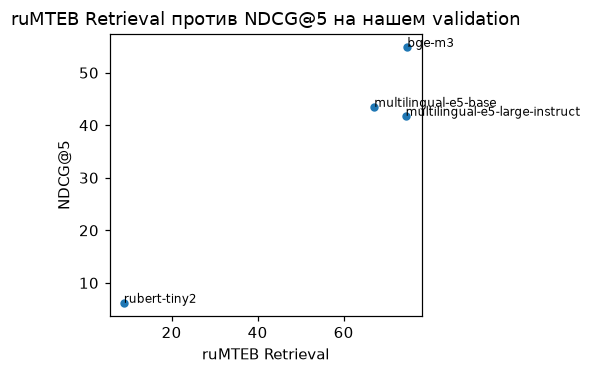

In [5]:
correlation = pd.DataFrame({
    mteb: {ours: spearmanr(model_table[mteb], model_table[ours]).statistic for ours in ("R@5", "NDCG@5", "MRR")}
    for mteb in ("ruMTEB Avg", "ruMTEB Retrieval")}).round(2)
display(correlation)
ax = model_table.plot.scatter(x="ruMTEB Retrieval", y="NDCG@5", figsize=(5, 3.5))
for name, row in model_table.iterrows():
    ax.annotate(name, (row["ruMTEB Retrieval"], row["NDCG@5"]), fontsize=8)
ax.set_title("ruMTEB Retrieval против NDCG@5 на нашем validation")
plt.tight_layout()

In [6]:
best_model = max(model_table.index, key=lambda name: tuple(model_table.loc[name, ["R@5", "NDCG@5"]]))
print("лучшая модель на validation (R@5, затем NDCG@5):", best_model)
best_vectors = model_vectors[best_model]
best_gold_vectors, best_latency_vectors, best_embed_latency = model_query_vectors[best_model]

лучшая модель на validation (R@5, затем NDCG@5): bge-m3


## 3. Векторная БД: Qdrant

Qdrant 1.19.2 в Docker, косинусная метрика, векторы лучшей модели. Конфигурации — разные точки
trade-off «точность / скорость / память»:

- **flat** — без графа, точный перебор всех векторов: эталон качества;
- **HNSW m=8, ef=16** — разреженный граф и узкий поиск: быстрее, но может терять соседей;
- **HNSW m=16, ef=64** — значения по умолчанию в Qdrant (m=16, ef_construct=100);
- **HNSW m=32, ef=128 + int8** — плотный граф и скалярная квантизация: в RAM — int8-копии векторов (в 4 раза
  меньше), исходные лежат на диске (mmap); найденные кандидаты пересчитываются по исходным (`rescore`).

Каждая конфигурация — в свежем контейнере, поэтому пик памяти при индексировании (`memory.peak` cgroup
контейнера) относится к одному индексированию. В пик входят страничный кэш файлов, которые Qdrant пишет
на диск, и куча после разбора загрузки (векторы приходят JSON-ом по HTTP), поэтому отдельно — **RAM индекса**:
контейнер перезапускается, Qdrant поднимает коллекцию с диска, и после запросов берётся собственная память
процесса плюс отображённые в память файлы (`anon` + `file_mapped`). Запросы и выдачи — после перезапуска.
Время запроса — медиана по 100 запросам (top-10, по одному запросу, HTTP-клиент на той же машине); векторы запросов
посчитаны заранее, время эмбеддинга запроса — в разделе 2.
**ANN recall@10** — доля точного топ-10 (flat), которую нашёл приближённый индекс. Граф HNSW Qdrant строит
в несколько потоков, и от сборки к сборке он разный, поэтому каждая конфигурация индексируется трижды:
в таблице — среднее по сборкам и минимум ANN recall, R@5 — средний и разброс по сборкам.

In [7]:
INDEX_CONFIGS = [
    IndexConfig("flat", hnsw_m=0),
    IndexConfig("HNSW m=8, ef=16", hnsw_m=8, ef_construct=64, hnsw_ef=16),
    IndexConfig("HNSW m=16, ef=64", hnsw_m=16, ef_construct=100, hnsw_ef=64),
    IndexConfig("HNSW m=32, ef=128 + int8", hnsw_m=32, ef_construct=200, hnsw_ef=128, int8=True, on_disk=True),
]


def qdrant_run(config: IndexConfig, vectors: np.ndarray, gold_vectors: dict, latency_vectors, label: str,
               repeat: int = 0) -> dict:
    """Индексирование в свежем контейнере, выдачи gold (top-POOL) и задержки 100 запросов; кэшируется,
    поэтому повторное исполнение ноутбука Docker не требует."""
    def compute() -> dict:
        with QdrantContainer() as qdrant:
            client = qdrant.client()
            seconds = build_collection(client, "chunks", vectors, config)
            peak = qdrant.peak_memory_mb()
            qdrant.restart()
            client = qdrant.client()
            vectordb.wait_loaded(client, "chunks")
            rankings, _ = vectordb.search(client, "chunks", list(gold_vectors.values()), config, POOL)
            _, latencies = vectordb.search(client, "chunks", latency_vectors, config, DEPTH)
            resident = qdrant.resident_memory_mb()  # после запросов: рабочий набор страниц уже в памяти
        return {"index_seconds": seconds, "peak_mb": peak, "resident_mb": resident, "latencies": latencies.tolist(),
                "rankings": dict(zip(gold_vectors, rankings, strict=True))}
    path = cache.path(f"qdrant_{label}", "json", vectors=array_fingerprint(vectors), image=vectordb.QDRANT_IMAGE,
                      qids=list(gold_vectors), queries=array_fingerprint(np.stack(list(gold_vectors.values()))),
                      latency_queries=array_fingerprint(np.asarray(latency_vectors)), limit=POOL, depth=DEPTH,
                      code=code_fingerprint(vectordb), measures=("peak", "resident_after_restart"), repeat=repeat,
                      **config.params())
    return load_or_compute(path, compute, load=read_json, save=write_json)


REPEATS = 3  # граф HNSW строится в несколько потоков и от сборки к сборке разный
index_runs = {c.name: [qdrant_run(c, best_vectors, best_gold_vectors, best_latency_vectors, best_model, repeat)
                       for repeat in range(REPEATS)] for c in INDEX_CONFIGS}
exact_top = {qid: ranked_ids(r) for qid, r in index_runs["flat"][0]["rankings"].items()}


def ann_recall(run: dict) -> float:
    return 100 * np.mean([metrics.overlap_at_k(ranked_ids(r), exact_top[qid], DEPTH)
                          for qid, r in run["rankings"].items()])


index_per_q = pd.concat([evaluate(name, "dense", run["rankings"]).assign(repeat=repeat)
                         for name, runs in index_runs.items() for repeat, run in enumerate(runs)])
index_table = pd.DataFrame([{
    "config": name, "индексирование, с": np.mean([r["index_seconds"] for r in runs]),
    "запрос, мс": np.median([t for r in runs for t in r["latencies"]]) * 1000,
    "p95, мс": np.percentile([t for r in runs for t in r["latencies"]], 95) * 1000,
    "пик RAM, МБ": np.mean([r["peak_mb"] for r in runs]), "RAM индекса, МБ": np.mean([r["resident_mb"] for r in runs]),
    "ANN recall@10, % (среднее)": np.mean([ann_recall(r) for r in runs]),
    "ANN recall@10, % (минимум)": min(ann_recall(r) for r in runs),
} for name, runs in index_runs.items()]).set_index("config")
r5_by_build = index_per_q[index_per_q["split"] == "validation"].groupby(["config", "repeat"], sort=False)["R@5"].mean()
index_table = index_table.join(summary(index_per_q, columns=["R@5", "NDCG@5"]))
index_table["R@5 (мин–макс по сборкам)"] = [f"{r5_by_build[name].min() * 100:.1f}–{r5_by_build[name].max() * 100:.1f}"
                                           for name in index_table.index]
index_table.round(2)

,"индексирование, с","запрос, мс","p95, мс","пик RAM, МБ","RAM индекса, МБ","ANN recall@10, % (среднее)","ANN recall@10, % (минимум)",R@5,NDCG@5,R@5 (мин–макс по сборкам)
config,,,,,,,,,,
flat,2.91,1.47,1.89,1985.89,1358.48,100.00,100.0,53.3,54.9,53.3–53.3
"HNSW m=8, ef=16",2.92,1.25,1.41,2021.16,1218.11,94.67,93.4,52.4,54.6,50.7–53.3
"HNSW m=16, ef=64",2.97,1.36,1.58,2041.07,1504.35,97.33,96.0,50.5,53.0,48.7–53.3
"HNSW m=32, ef=128 + int8",2.94,1.18,1.33,2095.02,823.32,98.40,97.6,51.0,53.4,49.8–53.3


### Scalability

Конфигурация HNSW m=16, ef=64 на 10 / 25 / 50 / 100% корпуса — случайная выборка чанков (seed 42).
Каждая доля — свежий контейнер.

,доля корпуса,векторов,"индексирование, с","запрос, мс","p95, мс","пик RAM, МБ","RAM индекса, МБ"
0,0.10,1977,0.41,1.03,1.12,348.75,514.99
1,0.25,4943,0.84,1.07,1.15,733.21,700.32
2,0.50,9886,1.53,1.10,1.23,1284.79,945.99
3,1.00,19773,2.87,1.26,1.40,2130.16,1266.02


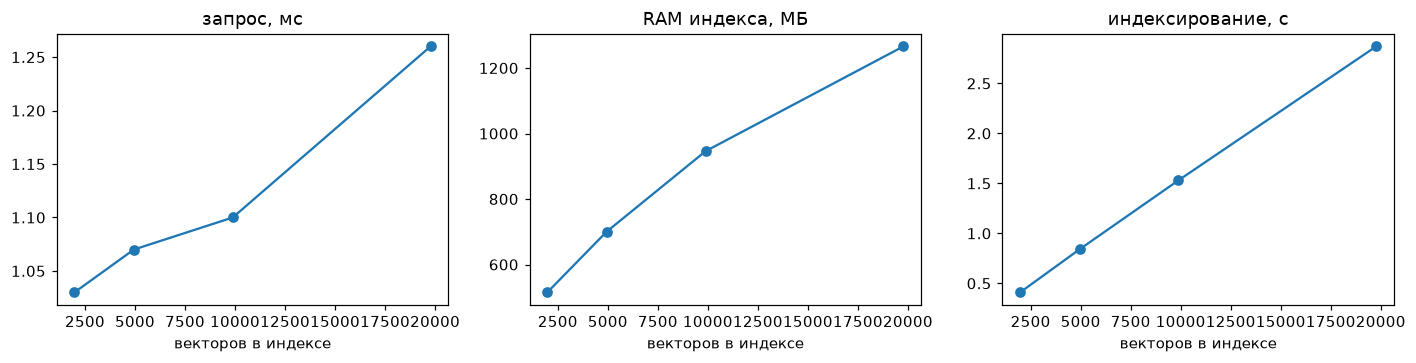

In [8]:
SCALE_CONFIG = INDEX_CONFIGS[2]
rng = random.Random(SEED)
scale_rows = []
for share in (0.1, 0.25, 0.5, 1.0):
    subset = sorted(rng.sample(range(len(best_vectors)), int(share * len(best_vectors))))
    run = qdrant_run(SCALE_CONFIG, best_vectors[subset], best_gold_vectors, best_latency_vectors,
                     f"{best_model}-scale{share}")
    scale_rows.append({"доля корпуса": share, "векторов": len(subset), "индексирование, с": run["index_seconds"],
                       "запрос, мс": np.median(run["latencies"]) * 1000,
                       "p95, мс": np.percentile(run["latencies"], 95) * 1000, "пик RAM, МБ": run["peak_mb"],
                       "RAM индекса, МБ": run["resident_mb"]})
scale_table = pd.DataFrame(scale_rows).round(2)
display(scale_table)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, column in zip(axes, ["запрос, мс", "RAM индекса, МБ", "индексирование, с"], strict=True):
    ax.plot(scale_table["векторов"], scale_table[column], marker="o")
    ax.set_title(column)
    ax.set_xlabel("векторов в индексе")
plt.tight_layout()

## 4. Sparse: BM25

`rank-bm25` (BM25Okapi), слова в нижнем регистре. Сетка:

- **k1** (насыщение частоты термина) — 0,1…3,0. Классический диапазон 1,2–2,0; ниже — частота почти
  не важна (короткие посты, где слово встречается раз), выше — почти линейный рост за повтор
  (длинные статьи, повторяющие имя героя);
- **b** (нормировка длины) — 0…1 целиком: от «длина не важна» до полной нормировки. В КТ 2 удаление
  подписей сделало посты короче и через b = 0,75 подняло их над патчноутами — сигнал, что b стоит понизить.

лучшие параметры (R@5, затем NDCG@5): k1=0.3, b=1.0


,,R@5,NDCG@5
k1,b,,
1.5,0.75,41.7,37.4
0.3,1.00,44.3,40.4


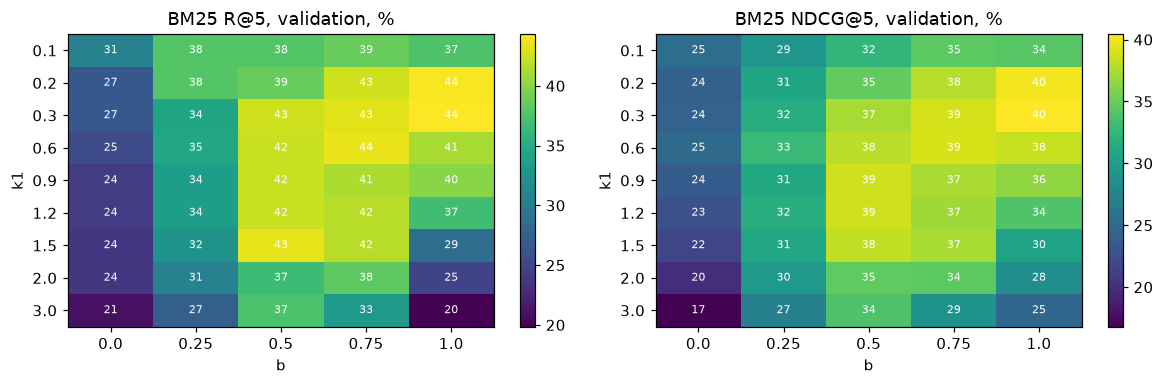

In [9]:
K1_GRID = (0.1, 0.2, 0.3, 0.6, 0.9, 1.2, 1.5, 2.0, 3.0)
B_GRID = (0.0, 0.25, 0.5, 0.75, 1.0)
bm25_corpus_tokens = [bm25_tokens(t) for t in texts]


def bm25_rankings(index: Bm25Index) -> dict:
    return {qid: index.search(q, POOL) for qid, q in queries.items()}


def bm25_grid_rankings() -> dict:
    """Выдачи BM25 для каждой пары (k1, b) — ключ «k1|b». Кэшируются только выдачи: метрики пересчитываются
    при каждом исполнении, поэтому правка gold или разбиения не подхватит старые цифры."""
    return {f"{k1}|{b}": bm25_rankings(Bm25Index.from_tokens(bm25_corpus_tokens, k1, b))
            for k1 in K1_GRID for b in B_GRID}


grid_rankings = load_or_compute(
    cache.path("bm25_grid_rankings", "json", texts=texts_fingerprint(texts), queries=sorted(queries.items()),
               k1=K1_GRID, b=B_GRID, pool=POOL, code=code_fingerprint(gigarag.patterns, gigarag.retrieval)),
    bm25_grid_rankings, load=read_json, save=write_json)
grid_per_q = pd.concat([evaluate(f"k1={k1}, b={b}", "bm25", grid_rankings[f"{k1}|{b}"]).assign(k1=k1, b=b)
                        for k1 in K1_GRID for b in B_GRID], ignore_index=True)
grid = grid_per_q[grid_per_q["split"] == "validation"].groupby(["k1", "b"])[["R@5", "NDCG@5"]].mean() * 100
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, column in zip(axes, ["R@5", "NDCG@5"], strict=True):
    table = grid[column].unstack("b")
    image = ax.imshow(table, cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(table.columns)), table.columns)
    ax.set_yticks(range(len(table.index)), table.index)
    ax.set_xlabel("b")
    ax.set_ylabel("k1")
    ax.set_title(f"BM25 {column}, validation, %")
    for (row, col), value in np.ndenumerate(table.to_numpy()):
        ax.text(col, row, f"{value:.0f}", ha="center", va="center", color="white", fontsize=7)
    fig.colorbar(image, ax=ax)
plt.tight_layout()
best_k1, best_b = max(grid.index, key=lambda params: tuple(grid.loc[params, ["R@5", "NDCG@5"]]))
print(f"лучшие параметры (R@5, затем NDCG@5): k1={best_k1}, b={best_b}")
grid.loc[[(1.5, 0.75), (best_k1, best_b)]].round(1)

In [10]:
(bm25_best, bm25_peak_mb), bm25_index_seconds = timed(
    lambda: traced_peak_mb(lambda: Bm25Index.build(texts, best_k1, best_b)))
bm25_default = Bm25Index.from_tokens(bm25_corpus_tokens, 1.5, 0.75)
bm25_query_seconds = np.array([timed(lambda q=q: bm25_best.search(q, POOL))[1] for q in latency_queries])
sparse_rankings = bm25_rankings(bm25_best)
print(f"BM25 k1={best_k1}, b={best_b}: индексирование {bm25_index_seconds:.1f} с (с токенизацией), "
      f"пик памяти {bm25_peak_mb:.0f} МБ, запрос — медиана {np.median(bm25_query_seconds) * 1000:.1f} мс")

BM25 k1=0.3, b=1.0: индексирование 1.3 с (с токенизацией), пик памяти 90 МБ, запрос — медиана 20.9 мс


## 5. Dense: лучшая модель + лучший индекс

Не новый эксперимент, а сборка: модель — лучшая на validation из раздела 2, индекс — самая быстрая
конфигурация Qdrant, которая не теряет соседей ни в одной из трёх сборок (минимум ANN recall@10 ≥ 99%).

In [11]:
lossless = index_table[index_table["ANN recall@10, % (минимум)"] >= 99]  # без потерь в каждой сборке
best_index = lossless["запрос, мс"].idxmin()
dense_rankings = index_runs[best_index][0]["rankings"]
dense_query_ms = best_embed_latency * 1000 + index_table.loc[best_index, "запрос, мс"]
print(f"dense: {best_model} + {best_index}; запрос = эмбеддинг {best_embed_latency * 1000:.1f} мс "
      f"+ Qdrant {index_table.loc[best_index, 'запрос, мс']:.1f} мс")

dense: bge-m3 + flat; запрос = эмбеддинг 4.0 мс + Qdrant 1.5 мс


## 6. Hybrid

Кандидаты — топ-100 BM25 (лучшие k1, b) и топ-100 dense (раздел 5).

- **RRF** (k = 60): score = Σ 1 / (60 + место); только места, без весов.
- **Взвешенная сумма**: alpha · dense + (1 − alpha) · BM25, каждый score min-max нормирован внутри своих
  100 кандидатов; alpha — от 0 (только BM25) до 1 (только dense) с шагом 0,1.

лучший alpha на validation: 0.6


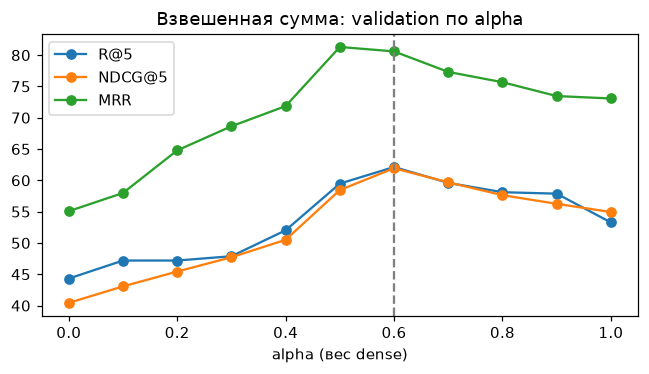

In [12]:
ALPHAS = np.round(np.arange(0, 1.01, 0.1), 1)
rrf_rankings = {qid: fusion.rrf_fusion([dense_rankings[qid], sparse_rankings[qid]], POOL) for qid in queries}


def weighted_rankings_for(alpha: float) -> dict:
    return {qid: fusion.weighted_fusion(dense_rankings[qid], sparse_rankings[qid], alpha, POOL) for qid in queries}


weighted_per_q = pd.concat([evaluate(f"alpha={alpha}", "hybrid", weighted_rankings_for(alpha)).assign(alpha=alpha)
                            for alpha in ALPHAS])
validation_weighted = weighted_per_q[weighted_per_q["split"] == "validation"]
alpha_curve = validation_weighted.groupby("alpha")[["R@5", "NDCG@5", "MRR"]].mean() * 100
best_alpha = max(alpha_curve.index, key=lambda alpha: tuple(alpha_curve.loc[alpha, ["R@5", "NDCG@5"]]))
ax = alpha_curve.plot(marker="o", figsize=(6, 3.5), title="Взвешенная сумма: validation по alpha")
ax.axvline(best_alpha, color="grey", linestyle="--")
ax.set_xlabel("alpha (вес dense)")
plt.tight_layout()
weighted_rankings = weighted_rankings_for(best_alpha)
print("лучший alpha на validation:", best_alpha)

In [13]:
pipelines = {"BM25": sparse_rankings, "dense": dense_rankings, "hybrid RRF": rrf_rankings,
             f"hybrid weighted α={best_alpha}": weighted_rankings}
pipeline_per_q = pd.concat([evaluate(name, "pipeline", r) for name, r in pipelines.items()])
display(summary(pipeline_per_q).join(summary(pipeline_per_q, "test", ["R@5", "NDCG@5"]).add_prefix("test ")))
display(metrics.paired_changes(pipeline_per_q.assign(retriever="—"), "dense", "hybrid RRF"))

,P@5,R@5,NDCG@5,MAP,MRR,test R@5,test NDCG@5
config,,,,,,,
BM25,20.0,44.3,40.4,37.5,55.1,33.1,49.6
dense,26.2,53.3,54.9,48.7,73.1,37.9,52.3
hybrid RRF,27.6,60.9,57.2,52.0,77.3,34.1,51.3
hybrid weighted α=0.6,29.7,62.1,61.9,56.1,80.6,47.6,61.9


,лучше,хуже,без изменений
retriever,,,
—,6,3,20


**Где hybrid выигрывает — по типам вопросов** (validation; для негативных — `near@5`, доля чанков «по теме,
но без ответа» в топ-5: меньше — меньше правдоподобного контекста для выдумки):

In [14]:
by_type = pipeline_per_q[pipeline_per_q["split"] == "validation"].pivot_table(
    index="config", columns="qtype", values=["R@5", "NDCG@5"], sort=False).mul(100).round(1)
negatives = pd.concat([near_negatives(name, r) for name, r in pipelines.items()])
by_type[("near@5", "negative")] = negatives.query("split == 'validation'").groupby(
    "config", sort=False)["near@5"].mean().mul(100).round(1)
by_type

R@5                     NDCG@5                      near@5
qtype                 factual composite abstract factual composite abstract negative
config                                                                              
BM25                     71.2      40.5      8.1    47.1      47.2     19.4     11.4
dense                    66.7      66.8     11.0    55.3      72.0     27.6     20.0
hybrid RRF               84.8      68.0     11.9    59.5      70.7     32.5     20.0
hybrid weighted α=0.6    84.8      69.8     14.3    66.1      74.7     35.4     17.1

Сколько вопросов каждого типа hybrid решил лучше / хуже каждого компонента (R@5, validation):

In [15]:
validation = pipeline_per_q[pipeline_per_q["split"] == "validation"]
wide = validation.pivot_table(index=["qtype", "qid"], columns="config", values="R@5")
hybrid_names = [name for name in pipelines if name.startswith("hybrid")]
pd.concat({f"{hybrid} vs {component}": pd.DataFrame({
    "лучше": (wide[hybrid] > wide[component]).groupby(level=0).sum(),
    "хуже": (wide[hybrid] < wide[component]).groupby(level=0).sum()})
    for hybrid in hybrid_names for component in ("BM25", "dense")}, axis=1)

hybrid RRF vs BM25      hybrid RRF vs dense      hybrid weighted α=0.6 vs BM25      hybrid weighted α=0.6 vs dense     
                       лучше хуже               лучше хуже                         лучше хуже                          лучше хуже
qtype                                                                                                                            
abstract                   2    3                   2    1                             3    2                              2    0
composite                  6    0                   2    2                             6    0                              2    1
factual                    2    0                   2    0                             2    0                              2    0

### Hybrid + фильтр по патчу из КТ 2

Фильтр метаданных из КТ 2: если вопрос называет патч, поиск идёт только среди чанков этого патча
(или упоминающих его). Это настоящий pre-filter: маска применяется к полному массиву score каждого поисковика
до отбора топ-100, поэтому подходящий чанк не теряется, даже если без фильтра он был бы ниже сотого места.
Dense здесь — точный перебор numpy по тем же векторам BGE-M3: Qdrant flat — тоже точный перебор, их выдачи
совпадают (проверка ниже). В проде это payload-фильтр Qdrant.

In [16]:
patch_masks = metadata.filter_masks(metadata.patch_filter(meta, texts), meta, queries)
best_hybrid = max(hybrid_names, key=lambda name: tuple(summary(pipeline_per_q).loc[name, ["R@5", "NDCG@5"]]))


exact_dense = {qid: top_k(best_vectors @ v, DEPTH) for qid, v in best_gold_vectors.items()}
flat_rankings = index_runs["flat"][0]["rankings"]
flat_match = np.mean([metrics.overlap_at_k(ranked_ids(exact_dense[qid]), ranked_ids(flat_rankings[qid]), DEPTH)
                      for qid in queries])
print(f"совпадение топ-10 numpy и Qdrant flat: {flat_match:.1%}")


def fuse_filtered(qid: str) -> list:
    mask = patch_masks.get(qid)
    dense = masked_top_k(best_vectors @ best_gold_vectors[qid], mask, POOL)
    sparse = masked_top_k(bm25_best.scores(queries[qid]), mask, POOL)
    if best_hybrid == "hybrid RRF":
        return fusion.rrf_fusion([dense, sparse], POOL)
    return fusion.weighted_fusion(dense, sparse, best_alpha, POOL)


filtered_rankings = {qid: fuse_filtered(qid) for qid in queries}
print(f"фильтр применяется к {len(patch_masks)} вопросам из {len(queries)}; база — {best_hybrid}")
filtered_per_q = evaluate(f"{best_hybrid} + фильтр по патчу", "pipeline", filtered_rankings)
summary(pd.concat([pipeline_per_q[pipeline_per_q["config"] == best_hybrid], filtered_per_q]))

совпадение топ-10 numpy и Qdrant flat: 99.8%


фильтр применяется к 34 вопросам из 50; база — hybrid weighted α=0.6


,P@5,R@5,NDCG@5,MAP,MRR
config,,,,,
hybrid weighted α=0.6,29.7,62.1,61.9,56.1,80.6
hybrid weighted α=0.6 + фильтр по патчу,31.0,66.0,60.2,61.0,79.8


## 7. Итоговая таблица

Строка — модель × индекс × пайплайн. Метрики — validation, R@5 и NDCG@5 — ещё и на test. Время запроса —
медиана по 100 запросам: dense = эмбеддинг запроса + поиск (numpy или Qdrant), hybrid = dense + BM25
(слияние — доли миллисекунды). RAM: у Qdrant — RAM рабочего индекса после перезапуска, у numpy —
массив векторов, у BM25 — аллокации Python при построении индекса; у hybrid — сумма компонентов.

In [17]:
bm25_ms = np.median(bm25_query_seconds) * 1000
dense_ram = index_table.loc[best_index, "RAM индекса, МБ"]
final_rows = []


def add_row(model, index, pipeline, per_q, query_ms, ram_mb):
    val, test = summary(per_q).iloc[0], summary(per_q, "test", ["R@5", "NDCG@5"]).iloc[0]
    final_rows.append({"модель": model, "индекс": index, "пайплайн": pipeline, **val.to_dict(),
                       "test R@5": test["R@5"], "test NDCG@5": test["NDCG@5"], "запрос, мс": query_ms,
                       "RAM, МБ": ram_mb})


for name in model_table.index:
    add_row(name, "numpy, точный", "dense", model_per_q[model_per_q["config"] == name],
            model_table.loc[name, "запрос с поиском, мс"], model_vectors[name].nbytes / 2 ** 20)
for name in index_table.index:
    add_row(best_model, f"Qdrant {name}", "dense", index_per_q[index_per_q["config"] == name],
            best_embed_latency * 1000 + index_table.loc[name, "запрос, мс"], index_table.loc[name, "RAM индекса, МБ"])
add_row("—", "BM25 k1=1.5, b=0.75", "sparse", evaluate("default", "bm25", bm25_rankings(bm25_default)), bm25_ms,
        bm25_peak_mb)
add_row("—", f"BM25 k1={best_k1}, b={best_b}", "sparse", pipeline_per_q[pipeline_per_q["config"] == "BM25"],
        bm25_ms, bm25_peak_mb)
for name in hybrid_names:
    add_row(best_model, f"Qdrant {best_index} + BM25", name, pipeline_per_q[pipeline_per_q["config"] == name],
            dense_query_ms + bm25_ms, dense_ram + bm25_peak_mb)
add_row(best_model, f"Qdrant {best_index} + BM25", f"{best_hybrid} + фильтр по патчу", filtered_per_q,
        dense_query_ms + bm25_ms, dense_ram + bm25_peak_mb)
final_table = pd.DataFrame(final_rows).round(1)
final_table

,модель,индекс,пайплайн,P@5,R@5,NDCG@5,MAP,MRR,test R@5,test NDCG@5,"запрос, мс","RAM, МБ"
0,rubert-tiny2,"numpy, точный",dense,2.8,8.0,6.2,5.6,8.9,0.0,0.0,1.5,23.5
1,multilingual-e5-base,"numpy, точный",dense,20.7,50.0,43.5,34.4,52.5,31.8,44.5,3.4,57.9
2,bge-m3,"numpy, точный",dense,26.2,53.3,54.9,48.7,73.1,37.9,52.3,5.9,77.2
3,multilingual-e5-large-instruct,"numpy, точный",dense,17.9,44.3,41.8,33.6,50.7,39.4,51.3,5.8,77.2
4,bge-m3,Qdrant flat,dense,26.2,53.3,54.9,48.7,73.1,37.9,52.3,5.4,1358.5
5,bge-m3,"Qdrant HNSW m=8, ef=16",dense,25.5,52.4,54.6,48.3,72.9,37.9,52.2,5.2,1218.1
6,bge-m3,"Qdrant HNSW m=16, ef=64",dense,25.3,50.5,53.0,46.2,70.7,31.8,48.6,5.3,1504.4
7,bge-m3,"Qdrant HNSW m=32, ef=128 + int8",dense,25.7,51.0,53.4,46.4,70.8,31.8,48.8,5.2,823.3
8,—,"BM25 k1=1.5, b=0.75",sparse,18.6,41.7,37.4,32.2,53.6,29.2,48.4,20.9,90.2
9,—,"BM25 k1=0.3, b=1.0",sparse,20.0,44.3,40.4,37.5,55.1,33.1,49.6,20.9,90.2


## 8. Выводы и рекомендация для КТ 4

- **Модели.** Лучшая на нашем корпусе — BGE-M3 (validation R@5 53,3, NDCG@5 54,9, MRR 73,1). Лидер ruMTEB
  по среднему, e5-large-instruct, — третья (R@5 44,3). С нашими метриками ранг по **среднему** ruMTEB
  коррелирует слабо (Спирмен 0,4), а по **Retrieval**-части — сильно (0,8). Из 23 задач ruMTEB к поиску
  относятся 5 (Retrieval и Reranking), остальные — классификация, кластеризация, STS и пары.
  rubert-tiny2 (ruMTEB Retrieval 8,9) для поиска непригодна и здесь (R@5 8,0): обучена на симметричном
  сходстве предложений, а не «вопрос → отрывок».
  BGE-M3 выигрывает на смешанном тексте патчноутов (русский + английские имена героев) и длинных чанках.
- **Индекс.** На 20 тыс. векторов все конфигурации отвечают за 1,2–1,5 мс, flat — за 1,5 мс без потерь.
  HNSW не ускоряет и теряет соседей, причём сколько — зависит от сборки: граф строится в несколько потоков,
  и за три сборки минимум ANN recall@10 — 93–98%, R@5 падал до 48,7. int8 с векторами на диске сокращает RAM
  (823 против 1 358 МБ), но тоже теряет соседей. Выбор — **flat**: единственный без потерь в каждой сборке,
  а при росте корпуса в 10 раз задержка выросла лишь с 1,0 до 1,3 мс. К HNSW стоит переходить от сотен
  тысяч векторов.
- **BM25.** Лучшие k1 = 0,3, b = 1,0 (R@5 41,7 → 44,3): частота слова в чанке почти не важна (короткие
  посты), длину нормировать полностью (длинные статьи не должны выигрывать числом слов).
- **Hybrid.** Взвешенная сумма с alpha = 0,6 лучше обоих компонентов и RRF (R@5 62,1 против 53,3 у dense
  и 44,3 у BM25; на test — 47,6 против 37,9). Выигрывает на всех типах вопросов:
  - на фактических — от BM25: точные имена и числа;
  - на составных — от dense: перефразированные пересказы;
  - на абстрактных — от обоих.

  RRF уступает взвешенной сумме: места не передают, насколько уверенно лидирует BM25 на вопросах с точным
  совпадением. На негативных hybrid подтягивает чуть меньше «похожих, но не ответ», чем dense (near@5 17 против 20%).
- **Рекомендация для КТ 4:** BGE-M3 + Qdrant flat + BM25 (k1 = 0,3, b = 1,0), взвешенная сумма alpha = 0,6
  и фильтр по патчу из запроса (настоящий pre-filter): validation R@5 66,0, MAP 61,0, MRR 79,8; test R@5 53,8.
  Узкое место — BM25 на `rank-bm25` (21 мс из 27 мс запроса): в КТ 4 его стоит заменить на разреженный индекс.